# Qué viaja en una llamada a un modelo

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | Un equipo municipal quiere que un modelo lea avisos de vecinos, pero no sabe qué viaja en cada llamada, cuánto tarda ni qué parte de la respuesta puede controlar. |
| **Producto** | Una función `preguntar`, una tabla de tiempos y tokens, y una decisión de uso escrita con tus mediciones. |
| **Recursos** | Ollama con `granite4:latest` (2,1 GB en disco y unos 2,7 GB de memoria mientras está cargado). La parte remota usa Gemini y es opcional: sin clave, esas celdas avisan y el cuaderno sigue. |

Un municipio recibe cientos de avisos por semana: cortes de colectivos, jornadas de vacunación, talleres de la escuela. Alguien propone que un modelo los lea y los ordene. Antes de construir nada, el equipo tiene que entender qué es una *llamada* a un modelo: qué se envía, qué vuelve y cuánto cuesta cada vuelta.

**¿Qué pasa exactamente cuando le pedimos algo a un modelo, y qué parte de la respuesta podemos controlar?**

> **Cómo se trabaja.** En clase se presenta cada tema con el código ya escrito. Después lo explorás por tu cuenta: ejecutás las celdas, leés las notas **Para mirar** y cambiás valores para ver qué pasa. Al final de cada bloque hay un **microlaboratorio**: una tabla te dice qué líneas completar y con qué, y la celda siguiente comprueba si quedó bien.

## Antes de empezar

**Ollama** es un programa que corre en tu computadora y responde pedidos por HTTP, como una página web que devuelve texto en lugar de HTML. La celda siguiente comprueba que esté activo y que tenga el modelo de la unidad.

In [1]:
import os
import time

import ollama
import requests

import utils

utils.comprobar_modelo_local()
utils.versiones(["requests", "ollama", "pandas", "google-genai"])

Ollama responde en http://localhost:11434 y tiene granite4:latest.


{'python': '3.12.13',
 'requests': '2.34.2',
 'ollama': '0.6.3',
 'pandas': '3.1.0',
 'google-genai': '2.33.0'}

## 1. Un pedido HTTP con un JSON adentro

Un pedido a un modelo es un diccionario con tres partes: **qué modelo**, **qué mensajes** y **qué opciones**. Lo mandamos a la dirección `/api/chat` del servidor local. El campo `stream` en `False` pide la respuesta entera de una vez, y no de a pedazos.

In [2]:
direccion = f"{utils.URL_OLLAMA}/api/chat"

aviso = "La escuela organiza una muestra de proyectos de ciencias."
instruccion = (
    "Clasificá el aviso en una palabra: educación, movilidad o salud.\n"
    f"Aviso: {aviso}"
)

pedido = {
    "model": utils.MODELO_LOCAL,
    "messages": [{"role": "user", "content": instruccion}],
    "stream": False,
    "options": {"temperature": 0},
}
print(pedido["messages"][0]["content"])

Clasificá el aviso en una palabra: educación, movilidad o salud.
Aviso: La escuela organiza una muestra de proyectos de ciencias.


Enviamos el pedido y miramos qué vuelve. Antes de leer el texto de la respuesta, fijate en cuántas cosas más trae.

In [3]:
respuesta_http = requests.post(direccion, json=pedido, timeout=120)
respuesta = respuesta_http.json()

print("Estado HTTP:", respuesta_http.status_code)
print("Campos de la respuesta:", list(respuesta.keys()))
print()
print("Texto del modelo:", respuesta["message"]["content"])

Estado HTTP: 200
Campos de la respuesta: ['model', 'created_at', 'message', 'done', 'done_reason', 'total_duration', 'load_duration', 'prompt_eval_count', 'prompt_eval_duration', 'eval_count', 'eval_duration']

Texto del modelo: Educación


Casi todos los campos son **mediciones**. Un **token** es el pedazo de texto que el modelo lee y escribe: una palabra corta, una sílaba o un signo. Los modelos se limitan, se miden y (los remotos) se cobran por tokens, no por palabras.

In [4]:
NANOSEGUNDOS_POR_SEGUNDO = utils.NANOSEGUNDOS_POR_SEGUNDO

mediciones = {
    "segundos totales": respuesta["total_duration"] / NANOSEGUNDOS_POR_SEGUNDO,
    "segundos de carga del modelo": (
        respuesta["load_duration"] / NANOSEGUNDOS_POR_SEGUNDO
    ),
    "tokens del pedido": respuesta.get("prompt_eval_count", 0),
    "tokens de la respuesta": respuesta["eval_count"],
}
utils.tabla([mediciones]).round(2)

,segundos totales,segundos de carga del modelo,tokens del pedido,tokens de la respuesta
0,0.33,0.08,44,3


> **Para mirar.**
>
> - La respuesta es un JSON: el texto del modelo está en `message` y el resto describe cuánto trabajó.
> - La respuesta fue `Educación` y tardó unos 0,3 segundos. El pedido tuvo 44 tokens; la respuesta, 3: la instrucción pesa mucho más que lo que el modelo contesta.
> - `prompt_eval_count` puede faltar cuando Ollama reutiliza un pedido ya procesado; por eso usamos `.get(..., 0)`.

## 2. Roles, y un modelo que no recuerda

Cada mensaje tiene un **rol**. El módulo `ollama` hace el mismo pedido HTTP que vimos, en una sola línea.

| Rol | Quién habla | Para qué sirve |
|---|---|---|
| `system` | Quien construye la aplicación | Fija la tarea y las reglas para todo el intercambio. |
| `user` | La persona que consulta | Trae el pedido concreto. |
| `assistant` | El modelo | Guarda lo que ya respondió. |

Probamos la misma pregunta sin `system` y con `system`.

In [5]:
pregunta = "Aviso: Hay vacunación antigripal en el centro de salud del barrio."
regla = (
    "Sos un asistente del municipio. Clasificás avisos de vecinos en una "
    "categoría: educación, movilidad o salud. Respondé solo con la categoría."
)

sin_rol_system = ollama.chat(
    model=utils.MODELO_LOCAL,
    messages=[{"role": "user", "content": pregunta}],
    options={"temperature": 0},
)
con_rol_system = ollama.chat(
    model=utils.MODELO_LOCAL,
    messages=[
        {"role": "system", "content": regla},
        {"role": "user", "content": pregunta},
    ],
    options={"temperature": 0},
)

utils.tabla([
    {"mensajes": "solo user", "respuesta": sin_rol_system.message.content},
    {"mensajes": "system + user", "respuesta": con_rol_system.message.content},
])

,mensajes,respuesta
0,solo user,"Estimado usuario,\n\nEs importante mantenerse informado sobre las campañas de vacunación contra la gripe, ya que estas son esenciales para proteger a la comunidad y prevenir la propagación de enfermedades infecciosas.\n\nLa vacuna contra la gripe se recomienda anualmente para personas de todas las edades, especialmente para aquellos con mayor riesgo de complicaciones graves debido a la gripe, como los niños pequeños, los adultos mayores y las personas con condiciones médicas preexistentes. La campaña de vacunación en el centro de salud del barrio es una oportunidad valiosa para que la comunidad reciba la vacuna y proteja su salud.\n\nSi desea recibir más información sobre la campaña de vacunación antigripal, como fechas específicas, horarios y requisitos previos, se recomienda contactar directamente al centro de salud del barrio o visitar su sitio web oficial. Además, puede consultar con un profesional de la salud para obtener recomendaciones personalizadas sobre la vacunación.\n\nRecuerde que mantenerse informado y tomar medidas preventivas es clave para proteger su salud y la de sus seres queridos. No dude en buscar más información o asistir a la campaña de vacunación si tiene alguna duda o preocupación.\n\nSaludos cordiales,\n[Nombre]"
1,system + user,Salud


> **Para mirar.** Con la misma pregunta y temperatura `0`, sin `system` el modelo escribió una carta de varios párrafos sobre la vacunación; con `system` respondió `Salud`. El rol `system` no agrega información: cambia qué tarea cree estar resolviendo el modelo.

**Experimentar.** Un modelo no guarda nada entre llamadas: cada pedido es independiente. Antes de ejecutar, predecí: si mandamos una segunda pregunta que depende de la primera, ¿el modelo entiende de qué hablamos?

In [6]:
aviso_de_ciencias = "Aviso: La escuela organiza una muestra de ciencias."
pregunta_dependiente = (
    "¿Y si el aviso fuera sobre un cambio de recorrido del 60?"
)

primer_pedido = [
    {"role": "system", "content": regla},
    {"role": "user", "content": aviso_de_ciencias},
]
primera = ollama.chat(
    model=utils.MODELO_LOCAL, messages=primer_pedido,
    options={"temperature": 0},
)

# La segunda llamada lleva SOLO la pregunta nueva.
segunda_sola = ollama.chat(
    model=utils.MODELO_LOCAL,
    messages=[{"role": "user", "content": pregunta_dependiente}],
    options={"temperature": 0},
)

print("Primera respuesta:", primera.message.content)
print()
print("Segunda respuesta, sin historial:")
print(segunda_sola.message.content[:300], "...")

Primera respuesta: educación

Segunda respuesta, sin historial:
Si el aviso fuera sobre un cambio de recorrido del 60, esto podría significar que la ruta o trayectoria planificada para un viaje, evento o actividad cambiaría. Sin embargo, sin más contexto específico, es difícil determinar exactamente qué tipo de cambio podría implicar.

Un cambio de recorrido del ...


La segunda respuesta no sabe qué se estaba clasificando: nadie se lo dijo. Para que haya conversación, **quien programa reenvía el historial** completo en cada llamada.

In [7]:
historial = primer_pedido + [
    {"role": "assistant", "content": primera.message.content},
    {"role": "user", "content": pregunta_dependiente},
]
segunda_con_historial = ollama.chat(
    model=utils.MODELO_LOCAL, messages=historial,
    options={"temperature": 0},
)

print("Mensajes enviados:", len(historial))
print("Segunda respuesta, con historial:")
print(segunda_con_historial.message.content)

Mensajes enviados: 4
Segunda respuesta, con historial:
movilidad


> **Para mirar.**
>
> - Sin historial, el modelo contestó con generalidades sobre «un cambio de recorrido del 60» y no clasificó nada.
> - Con cuatro mensajes (`system`, `user`, `assistant`, `user`) respondió `movilidad`.
> - La «memoria» de un chat es la lista de mensajes que se reenvía. Cuanto más larga, más tokens pesa cada llamada.

## 3. Temperatura: la misma pregunta, cinco veces

La **temperatura** regula cuánto se aparta el modelo de la palabra más probable en cada paso. Con `0` elige siempre la más probable; con valores altos se arriesga más. Pedimos la misma frase cinco veces con dos temperaturas.

In [8]:
pedido_abierto = [
    {
        "role": "user",
        "content": (
            "Escribí una sola frase para anunciar un taller de escritura "
            "en la biblioteca barrial."
        ),
    }
]

frases = []
for temperatura in (0.0, 1.5):
    for corrida in range(1, 6):
        respuesta_abierta = ollama.chat(
            model=utils.MODELO_LOCAL,
            messages=pedido_abierto,
            options={"temperature": temperatura},
        )
        frases.append({
            "temperatura": temperatura,
            "corrida": corrida,
            "frase": respuesta_abierta.message.content.strip(),
        })

utils.tabla(frases)

,temperatura,corrida,frase
0,0.0,1,"""¡Descubre tu voz con nuestro nuevo taller de escritura gratuito, abierto a todos los vecinos que buscan mejorar sus habilidades literarias!"""
1,0.0,2,"""¡Descubre tu voz con nuestro nuevo taller de escritura gratuito, abierto a todos los vecinos que buscan mejorar sus habilidades literarias!"""
2,0.0,3,"""¡Descubre tu voz con nuestro nuevo taller de escritura gratuito, abierto a todos los vecinos que buscan mejorar sus habilidades literarias!"""
3,0.0,4,"""¡Descubre tu voz con nuestro nuevo taller de escritura gratuito, abierto a todos los vecinos que buscan mejorar sus habilidades literarias!"""
4,0.0,5,"""¡Descubre tu voz con nuestro nuevo taller de escritura gratuito, abierto a todos los vecinos que buscan mejorar sus habilidades literarias!"""
5,1.5,1,"""Únete a nuestro próximo taller gratuito de escritura en la biblioteca, donde aprenderás consejos prácticos y técnicas para mejorar tus habilidades literarias."""
6,1.5,2,"""¡Únete a nuestro Taller de Escritura abierto al público en la Biblioteca Comunitaria, donde exploraremos creatividad y habilidades literarias en un ambiente acogedor!"""
7,1.5,3,"""Descubre el poder de tus palabras: Nuestro próximo taller de escritura te guía hacia expresar historias únicas y conectar con tu comunidad, todos los domingos a partir de las 2 p.m., en la tranquilidad de nuestra biblioteca vecinal."""
8,1.5,4,"**Talleres Creativos:** ¡Descubre el arte de escribir con nuestro nuevo taller en la Biblioteca Barrial, ideado para todos los amantes de la palabra y los nuevos escritores aspirantes!"
9,1.5,5,"¡Descubre tu voz y perfecciona tus habilidades literarias con nuestro próximo Taller de Escritura, gratuitamente disponible en nuestra Biblioteca Comunitaria! ¡Únete a nosotros para un viaje creativo lleno de inspiración y aprendizaje compartido!"


In [9]:
frases_distintas = {}
for temperatura in (0.0, 1.5):
    frases_de_esta_temperatura = set()
    for fila in frases:
        if fila["temperatura"] == temperatura:
            frases_de_esta_temperatura.add(fila["frase"])
    frases_distintas[temperatura] = len(frases_de_esta_temperatura)

frases_distintas

{0.0: 1, 1.5: 5}

> **Para mirar.**
>
> - Con temperatura `0` las cinco frases fueron idénticas (1 distinta). Con `1.5` las cinco fueron distintas (5).
> - Temperatura baja no significa respuesta correcta: significa respuesta **repetible**. Una respuesta repetible puede ser repetidamente equivocada.
> - Para clasificar avisos conviene repetibilidad. Para redactar variantes de un texto, no.

### Microlaboratorio 1 — Una función para cada llamada

**Tarea.** Encapsular la llamada en una función que devuelva el texto y sus mediciones.  
**Producto.** `preguntar`, comprobada.  
**Antes de empezar.** Secciones 1 a 3.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `"temperature"` | la temperatura que recibe la función | el argumento `temperatura`, sin comillas |
| (2) `segundos` | los segundos totales | `respuesta.total_duration` dividido por `NANOSEGUNDOS_POR_SEGUNDO` |
| (3) `tokens_salida` | los tokens de la respuesta | el campo `respuesta.eval_count` |

**Comprobación.** Mide que haya tiempo y tokens, y que una temperatura alta cambie las respuestas.

> **Ayuda 1.** Mirá la sección 3: ahí la temperatura se pasa dentro de `options`.  
> **Ayuda 2.** En la sección 1 convertimos nanosegundos a segundos con una división.

In [10]:
def preguntar(mensajes: list[dict], temperatura: float = 0.0) -> dict:
    """Hace una llamada al modelo local y devuelve texto y mediciones.

    Args:
        mensajes: Lista de mensajes con "role" y "content".
        temperatura: Cuanto se aparta el modelo de la palabra mas probable.

    Returns:
        Diccionario con texto, segundos, segundos_carga, tokens_entrada
        y tokens_salida.
    """
    respuesta = ollama.chat(
        model=utils.MODELO_LOCAL,
        messages=mensajes,
        options={"temperature": 0.0},  # COMPLETAR (1)
    )
    segundos = 0.0  # COMPLETAR (2)
    tokens_salida = 0  # COMPLETAR (3)
    return {
        "texto": respuesta.message.content.strip(),
        "segundos": segundos,
        "segundos_carga": respuesta.load_duration / NANOSEGUNDOS_POR_SEGUNDO,
        "tokens_entrada": respuesta.prompt_eval_count or 0,
        "tokens_salida": tokens_salida,
    }


prueba = preguntar(pedido_abierto, temperatura=2.0)
repeticiones = set()
for corrida in range(4):
    repeticiones.add(preguntar(pedido_abierto, temperatura=2.0)["texto"])

utils.comprobar(
    prueba["segundos"] > 0 and prueba["tokens_salida"] > 0,
    "revisa (2) y (3): segundos y tokens_salida tienen que ser mayores que 0",
)
utils.comprobar(
    len(repeticiones) > 1,
    "revisa (1): con temperatura 2.0 las cuatro frases no pueden ser iguales",
)

Todavia no: revisa (2) y (3): segundos y tokens_salida tienen que ser mayores que 0
Todavia no: revisa (1): con temperatura 2.0 las cuatro frases no pueden ser iguales


A partir de acá usamos la versión completa de la función, `utils.preguntar`, que hace lo mismo que la tuya. Así las secciones siguientes muestran mediciones reales aunque todavía no hayas resuelto el microlaboratorio.

## 4. El mismo pedido, a un modelo remoto

Un modelo remoto vive en servidores de otra organización. El pedido es parecido (modelo, mensajes, opciones) pero viaja por internet y exige una **clave de API**. Gemini ofrece una clave gratuita en [aistudio.google.com/apikey](https://aistudio.google.com/apikey), con límites de pedidos por minuto: por eso evitamos ráfagas.

> **Precaución.** Lo que enviás a un servicio remoto sale de tu computadora. Con los avisos sintéticos de esta unidad no hay problema; con mensajes reales de vecinos habría que decidirlo antes, porque incluyen nombres, direcciones o datos de salud.

La clave se guarda en un archivo `.env` (copiá `.env.example`), nunca dentro del cuaderno. Sin clave, esta sección se omite y el resto sigue funcionando.

In [11]:
from google import genai
from google.genai import types

if utils.hay_clave("GEMINI_API_KEY"):
    cliente_gemini = genai.Client(api_key=os.getenv("GEMINI_API_KEY"))
    print(f"Gemini listo: {utils.MODELO_GEMINI}")
else:
    cliente_gemini = None
    utils.avisar_sin_clave("GEMINI_API_KEY")

Sin GEMINI_API_KEY: se omite esta parte. Copia .env.example como .env, completa la clave y reinicia el kernel.


In [12]:
def preguntar_a_gemini(sistema: str, consulta: str) -> dict:
    """Hace una llamada a Gemini y devuelve texto y mediciones.

    Args:
        sistema: Instruccion fija, equivalente al rol system.
        consulta: Pedido concreto, equivalente al rol user.

    Returns:
        Diccionario con texto, segundos, tokens_entrada y tokens_salida.
        Si la llamada falla, devuelve un diccionario con el error.
    """
    inicio = time.perf_counter()
    try:
        respuesta_remota = cliente_gemini.models.generate_content(
            model=utils.MODELO_GEMINI,
            contents=consulta,
            config=types.GenerateContentConfig(
                system_instruction=sistema,
                temperature=0.0,
            ),
        )
    except genai.errors.APIError as error:
        return {"texto": f"Error de la API: {error}", "segundos": 0.0,
                "tokens_entrada": 0, "tokens_salida": 0}
    uso = respuesta_remota.usage_metadata
    return {
        "texto": (respuesta_remota.text or "").strip(),
        "segundos": time.perf_counter() - inicio,
        "tokens_entrada": uso.prompt_token_count or 0,
        "tokens_salida": uso.candidates_token_count or 0,
    }

In [13]:
mensajes_de_prueba = [
    {"role": "system", "content": regla},
    {"role": "user", "content": pregunta},
]

filas_comparacion = []
local = utils.preguntar(mensajes_de_prueba)
filas_comparacion.append({
    "modelo": utils.MODELO_LOCAL, "respuesta": local["texto"],
    "segundos": round(local["segundos"], 2),
    "tokens_salida": local["tokens_salida"],
})

if cliente_gemini is not None:
    remoto = preguntar_a_gemini(regla, pregunta)
    filas_comparacion.append({
        "modelo": utils.MODELO_GEMINI, "respuesta": remoto["texto"],
        "segundos": round(remoto["segundos"], 2),
        "tokens_salida": remoto["tokens_salida"],
    })

utils.tabla(filas_comparacion)

,modelo,respuesta,segundos,tokens_salida
0,granite4:latest,Salud,0.46,3


> **Para mirar.** Si hay clave, la tabla suma una fila para Gemini. Compará tres cosas: si las respuestas coinciden, cuántos segundos más tarda el modelo que viaja por internet y cuántos tokens usa. Con un solo aviso no podés concluir que un modelo sea mejor que el otro; la comparación de calidad llega en el cuaderno 02.

## 5. Medir antes de decidir

Una sola llamada no alcanza para decidir. Tomamos seis avisos de la unidad 010 (dos por categoría, sintéticos, CC0) y medimos cada llamada. Antes, descargamos el modelo de la memoria para ver qué cuesta **la primera** llamada.

In [14]:
registros = utils.cargar_json("clasificacion.json")

avisos_de_prueba = []
cantidad_por_categoria = {"educación": 0, "movilidad": 0, "salud": 0}
for registro in registros:
    categoria = registro["etiqueta"]
    if cantidad_por_categoria[categoria] < 2:
        avisos_de_prueba.append(registro)
        cantidad_por_categoria[categoria] += 1

print(f"Avisos de prueba: {len(avisos_de_prueba)} de {len(registros)}")

Avisos de prueba: 6 de 36


In [15]:
# keep_alive=0 le pide a Ollama que libere el modelo de la memoria.
ollama.generate(model=utils.MODELO_LOCAL, prompt="", keep_alive=0)

mediciones_locales = []
for registro in avisos_de_prueba:
    mensajes = [
        {"role": "system", "content": regla},
        {"role": "user", "content": f"Aviso: {registro['texto']}"},
    ]
    resultado = utils.preguntar(mensajes)
    mediciones_locales.append({
        "etiqueta_real": registro["etiqueta"],
        "respuesta": resultado["texto"],
        "segundos": round(resultado["segundos"], 2),
        "segundos_carga": round(resultado["segundos_carga"], 2),
        "tokens_entrada": resultado["tokens_entrada"],
        "tokens_salida": resultado["tokens_salida"],
    })

utils.tabla(mediciones_locales)

,etiqueta_real,respuesta,segundos,segundos_carga,tokens_entrada,tokens_salida
0,educación,educación,0.84,0.49,76,3
1,educación,educación,0.21,0.04,70,3
2,movilidad,movilidad,0.23,0.04,74,4
3,movilidad,movilidad,0.24,0.04,70,4
4,salud,salud,0.21,0.04,69,3
5,salud,salud,0.21,0.04,68,3


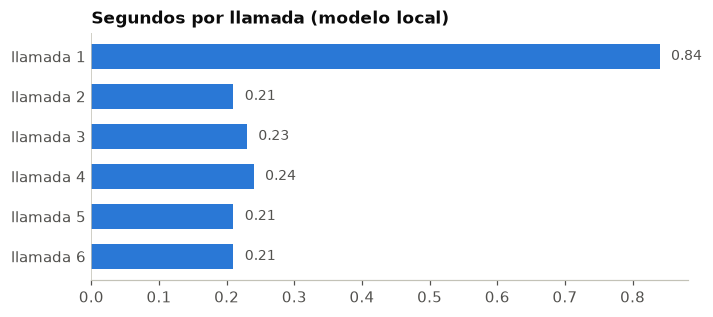

In [16]:
nombres_de_barras = []
segundos_de_cada_llamada = []
numero_de_llamada = 0
for fila in mediciones_locales:
    numero_de_llamada += 1
    nombres_de_barras.append(f"llamada {numero_de_llamada}")
    segundos_de_cada_llamada.append(fila["segundos"])

utils.dibujar_barras(
    nombres_de_barras,
    segundos_de_cada_llamada,
    titulo="Segundos por llamada (modelo local)",
)

> **Para mirar.**
>
> - La primera llamada tardó 0,84 s, de los cuales 0,49 s fueron de carga del modelo en memoria. Las cinco siguientes tardaron alrededor de 0,2 s cada una. Estos tiempos cambian en cada ejecución y en cada computadora.
> - Las seis respuestas coinciden con la etiqueta real, y cada una usa 3 o 4 tokens.
> - Seis avisos no son una evaluación: muestran un orden de magnitud, no el desempeño. La calidad de la clasificación se mide con las 36 etiquetas en el cuaderno 02.
> - Los segundos dependen de esta computadora. En otra, con otra memoria o procesador, serán distintos.

### Microlaboratorio 2 — Una decisión con tus propias mediciones

**Tarea.** Calcular el tiempo típico de una llamada local y escribir cuándo usarías cada camino.  
**Producto.** `promedio_de_segundos`, el valor medido y `mi_decision`.  
**Antes de empezar.** Secciones 4 y 5.

| Paso | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `total` | la suma de los `segundos` de todas las filas | un bucle `for` que acumula `fila["segundos"]` |
| (2) `promedio` | el total dividido la cantidad de filas | `len(filas)` |
| Paso 3 | tu decisión en `mi_decision` | texto de al menos 25 palabras |

En el paso 3, escribí **cuándo usarías el modelo local y cuándo uno remoto** para los avisos del municipio. Apoyate en lo que mediste (tiempo, tokens, qué sale de tu computadora). Una decisión condicional dice «si…, entonces…», no «el mejor es…».

> **Ayuda 1.** El bucle es igual al que acumula `cantidad` en otras unidades: se empieza en `0.0` y se suma en cada vuelta.  
> **Ayuda 2.** Si tenés dudas sobre la decisión, releé la **Precaución** de la sección 4.

In [17]:
def promedio_de_segundos(filas: list[dict]) -> float:
    """Calcula el promedio de la clave "segundos" de una lista de filas.

    Args:
        filas: Lista de diccionarios con la clave "segundos".

    Returns:
        Promedio de segundos por fila.
    """
    total = 0.0
    for fila in filas:
        total += 0.0  # COMPLETAR (1)
    promedio = 0.0  # COMPLETAR (2)
    return promedio


filas_de_prueba = [{"segundos": 1.0}, {"segundos": 3.0}]
promedio_de_prueba = promedio_de_segundos(filas_de_prueba)
utils.comprobar(
    abs(promedio_de_prueba - 2.0) < 1e-9,
    "revisa (1) y (2): el promedio de 1.0 y 3.0 tiene que ser 2.0",
)

# PASO 2: calculamos el promedio con tus mediciones, sin la llamada fria.
llamadas_en_caliente = mediciones_locales[1:]
promedio_local = promedio_de_segundos(llamadas_en_caliente)
print(f"Promedio local en caliente: {promedio_local:.2f} segundos")

# PASO 3: escribi tu decision.
mi_decision = ""
utils.comprobar(
    len(mi_decision.split()) >= 25,
    "escribi al menos 25 palabras en mi_decision",
)

Todavia no: revisa (1) y (2): el promedio de 1.0 y 3.0 tiene que ser 2.0
Promedio local en caliente: 0.00 segundos
Todavia no: escribi al menos 25 palabras en mi_decision


## Qué te llevás

- Una llamada es un **pedido con modelo, mensajes y opciones**, y una respuesta que además de texto trae tiempos y tokens.
- El modelo **no recuerda**: la conversación es el historial que reenvía quien programa. La temperatura cambia la repetibilidad, no la corrección.
- Local y remoto se comparan midiendo **tiempo, tokens y qué datos salen de tu computadora**, y la decisión es condicional.

**Sigue:** cómo escribir el pedido para que la tarea (clasificar un aviso) salga bien y se pueda medir (cuaderno 02).